# Knowledge Distillation for Blood Cell Classification

## Project question and current progress

**Research question:** Does output-based knowledge distillation from a fixed DenseNet-121 teacher improve a small CNN compared with conventional training of the same CNN?

This notebook is the central project record. It currently covers initial data exploration and teacher verification. Student training and distillation have **not** been performed. Future sections will be added here as experiments are completed; no placeholder is presented as a result.

**Two execution modes**

| Mode | Purpose | Requirements |
|---|---|---|
| `analysis` (default) | Recompute metrics from saved predictions, inspect figures, and discuss results | `requirements-analysis.txt` and the versioned result files; no GPU, weights, raw dataset, or network |
| `full` | Additionally run the initial raw-data exploration; optionally reevaluate the teacher | Full requirements and local data; teacher reevaluation additionally requires weights and CUDA |

Use **Restart Kernel and Run All** in `analysis` mode for the partner workflow. Switching modes requires a fresh kernel. Downloads and teacher reevaluation are separate opt-ins. Neither mode contains student training code.

In [2]:
# Start here. Analysis never loads model libraries, weights, or raw images.
RUN_MODE = "analysis"
ALLOW_DOWNLOADS = False
REEVALUATE_TEACHER = False

if RUN_MODE not in {"analysis", "full"}:
    raise ValueError("RUN_MODE must be 'analysis' or 'full'.")
if RUN_MODE == "analysis" and (ALLOW_DOWNLOADS or REEVALUATE_TEACHER):
    raise ValueError("Downloads and teacher reevaluation are available only in full mode.")
print(f"Mode: {RUN_MODE}; downloads: {ALLOW_DOWNLOADS}; teacher reevaluation: {REEVALUATE_TEACHER}")

Mode: analysis; downloads: False; teacher reevaluation: False


In [3]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")

# Resolve paths from the project root or notebooks/ without a machine-specific path.
source_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src" / "teacher_analysis.py").is_file()),
    None,
)
if source_root is None:
    raise FileNotFoundError("Missing src/teacher_analysis.py. Open the notebook inside the project and pull the shared code from Git.")
if str(source_root / "src") not in sys.path:
    sys.path.insert(0, str(source_root / "src"))

from teacher_analysis import find_project_root, load_teacher_analysis, teacher_table, per_class_table

PROJECT_ROOT = find_project_root(Path.cwd())
RESULTS_DIR = PROJECT_ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 12)
print("Project root:", PROJECT_ROOT)

Matplotlib is building the font cache; this may take a moment.


Project root: C:\Users\Asus\.codex\.chatgpt-projects\g-p-6af1b96cac6c8191bb99f4cd7ed6e2f1\central-notebook\analysis-only-project


## 1. Initial data loading and exploration

BloodMNIST is an eight-class RGB blood-cell classification dataset. We use the official train, validation, and test splits at 224 × 224 pixels. The split names alone do not establish patient-level separation.

In `analysis` mode, this section uses a small versioned snapshot derived from the verified local dataset: counts, class labels, and a saved preview. The full-resolution dataset is not needed. The original notebook's initial loading, sample display, label inspection, and class-distribution exploration are retained below, with raw-data operations gated by `full` mode.

In [4]:
summary_path = RESULTS_DIR / "data_summary.json"
if not summary_path.is_file():
    raise FileNotFoundError("Missing results/data_summary.json. Pull the saved analysis artifacts from Git; do not download data for analysis.")
data_summary = json.loads(summary_path.read_text(encoding="utf-8"))
class_names = data_summary["class_names"]
split_counts = pd.DataFrame({"Split": list(data_summary["counts"]), "Images": list(data_summary["counts"].values())})
display(split_counts)
display(pd.DataFrame({"Label": range(8), "Class": class_names}))
print("Image shape (H, W, C):", tuple(data_summary["input_shape"]))
print("First ten training labels:", data_summary["first_ten_training_labels"])

,Split,Images
0,train,11959
1,val,1712
2,test,3421


,Label,Class
0,0,basophil
1,1,eosinophil
2,2,erythroblast
3,3,"immature granulocytes(myelocytes, metamyelocyt..."
4,4,lymphocyte
5,5,monocyte
6,6,neutrophil
7,7,platelet


Image shape (H, W, C): (224, 224, 3)
First ten training labels: [7, 3, 6, 6, 7, 6, 2, 2, 7, 2]


In [5]:
# Full-mode equivalent of the original initial data-loading cells.
if RUN_MODE == "full":
    data_dir = PROJECT_ROOT / "data"
    local_data = data_dir / "bloodmnist_224.npz"
    if not ALLOW_DOWNLOADS and not local_data.is_file():
        raise FileNotFoundError("Full mode needs local data/bloodmnist_224.npz. Downloads are disabled.")
    try:
        import medmnist
        from medmnist import INFO
    except ImportError as exc:
        raise RuntimeError("Full mode requires requirements.txt; the analysis environment is intentionally smaller.") from exc
    DataClass = getattr(medmnist, INFO["bloodmnist"]["python_class"])
    train_dataset = DataClass(split="train", root=str(data_dir), download=ALLOW_DOWNLOADS, size=224)
    val_dataset = DataClass(split="val", root=str(data_dir), download=ALLOW_DOWNLOADS, size=224)
    test_dataset = DataClass(split="test", root=str(data_dir), download=ALLOW_DOWNLOADS, size=224)
    actual_counts = {"train": len(train_dataset), "val": len(val_dataset), "test": len(test_dataset)}
    if actual_counts != data_summary["counts"]:
        raise ValueError("Local data counts disagree with the saved data snapshot.")
    actual_class_counts = np.bincount(train_dataset.labels.reshape(-1), minlength=8)
    if not np.array_equal(actual_class_counts, data_summary["class_counts"]["train"]):
        raise ValueError("Training class counts disagree with the saved snapshot.")
    print("Local raw data loaded and checked:", actual_counts)
else:
    print("Analysis mode: raw-data loading skipped.")

Analysis mode: raw-data loading skipped.


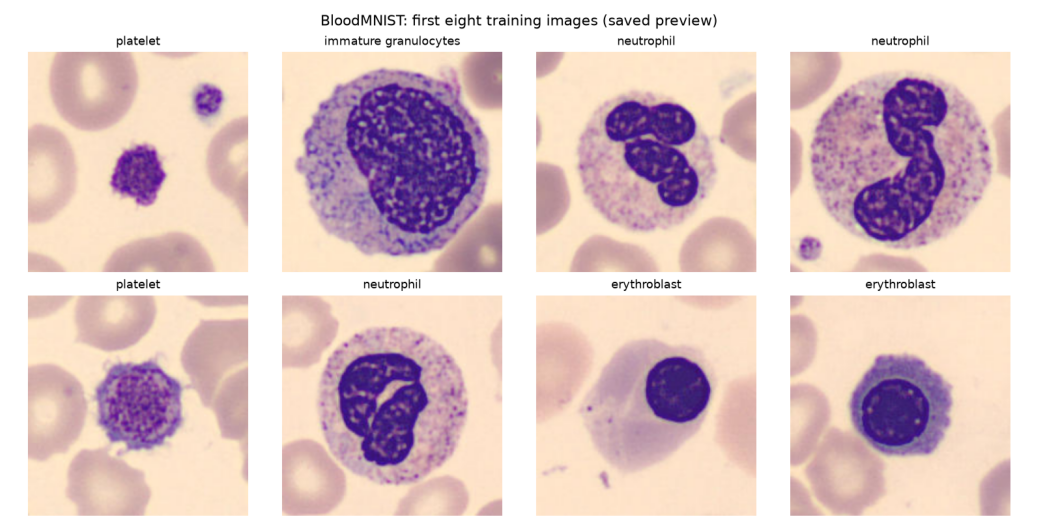

In [6]:
# The preview contains only eight saved training examples, not the raw dataset.
preview_path = RESULTS_DIR / "figures" / "data_samples.png"
if not preview_path.is_file():
    raise FileNotFoundError("Missing saved preview: results/figures/data_samples.png")
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(plt.imread(preview_path))
ax.axis("off")
plt.show()

if RUN_MODE == "full":
    # Show the same first-eight-image exploration directly from local data.
    fig, axes = plt.subplots(2, 4, figsize=(12, 6), constrained_layout=True)
    for i, ax in enumerate(axes.flat):
        image, label = train_dataset[i]
        ax.imshow(image)
        ax.set_title(class_names[int(label.item())].split("(")[0].strip(), fontsize=10)
        ax.axis("off")
    plt.show()

,Label,Class,Training images,Training share (%)
0,0,basophil,852,7.12
1,1,eosinophil,2181,18.24
2,2,erythroblast,1085,9.07
3,3,"immature granulocytes(myelocytes, metamyelocyt...",2026,16.94
4,4,lymphocyte,849,7.10
5,5,monocyte,993,8.30
6,6,neutrophil,2330,19.48
7,7,platelet,1643,13.74


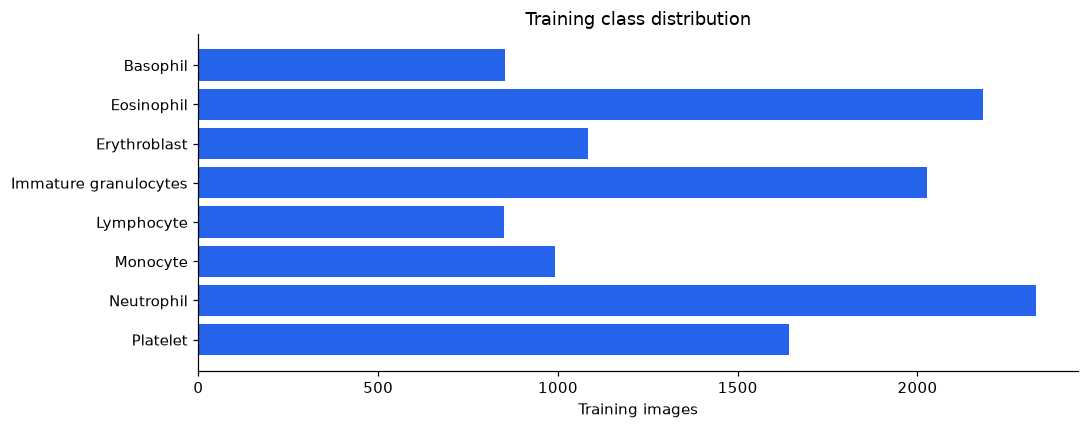

In [7]:
training_counts = np.asarray(data_summary["class_counts"]["train"])
training_distribution = pd.DataFrame({"Label": range(8), "Class": class_names, "Training images": training_counts, "Training share (%)": 100 * training_counts / training_counts.sum()})
display(training_distribution.round(2))
short_names = [name.split("(")[0].strip().capitalize() for name in class_names]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(short_names, training_counts, color="#2563eb")
ax.set(xlabel="Training images", title="Training class distribution")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Class sizes differ. **Accuracy** is the fraction of all correctly classified images, whereas **Balanced Accuracy** is the mean recall over the eight classes, giving each class equal weight. Balanced Accuracy is our primary selection/reporting metric. Labels and class order remain fixed throughout the project.

## 2. Teacher verification: protocol and fixed choice

The teacher is a pretrained **DenseNet-121** with eight output classes. The fixed checkpoint was selected **before inspecting local test performance**, using seed **71397589**. The authors also released two independently trained checkpoints of the same architecture; these are reference runs for the published mean and standard deviation. They are **not an ensemble**, and they do not replace the fixed teacher.

Verification used the native 224 × 224 RGB images, converted to float32 in [0, 1] and normalized using the checkpoint's `config.json`. No evaluation augmentation was applied. Weights were loaded strictly from safetensors, all parameters were frozen, and evaluation used `eval()` and `inference_mode()`. Model parameters and BatchNorm buffers were checked for changes. No training took place.

The next cell validates saved CSV probabilities, class indices, sample counts, confusion matrices and summary metrics. Missing or inconsistent artifacts produce an error; they never trigger downloads or model inference.

In [8]:
bundle = load_teacher_analysis(RESULTS_DIR)
report = bundle["report"]
PRIMARY_SEED = report["primary_teacher_seed"]
if class_names != bundle["class_names"]:
    raise ValueError("EDA and teacher reports use different class orders.")
if data_summary["source_sha256"] != report["data"]["sha256"]:
    raise ValueError("EDA snapshot and teacher report refer to different data files.")
for split in ("val", "test"):
    expected_support = data_summary["class_counts"][split]
    for teacher in report["teachers"]:
        actual_support = bundle["metrics"][(teacher["seed"], split)]["confusion_matrix"].sum(axis=1)
        if not np.array_equal(actual_support, expected_support):
            raise ValueError("Saved predictions disagree with the data-summary class counts.")
print("Validated saved predictions and metrics for", len(report["teachers"]), "checkpoints.")
print("Fixed teacher seed:", PRIMARY_SEED)
primary_record = next(teacher for teacher in report["teachers"] if teacher["seed"] == PRIMARY_SEED)
display(pd.DataFrame({"Channel": ["R", "G", "B"], "Mean": primary_record["normalization"]["mean"], "Std": primary_record["normalization"]["std"]}))

Validated saved predictions and metrics for 3 checkpoints.
Fixed teacher seed: 71397589


,Channel,Mean,Std
0,R,0.7961,0.2265
1,G,0.6596,0.2598
2,B,0.6964,0.0962


### 2.1 Primary teacher results

The following results describe the **single fixed teacher** that will supply soft targets for future distillation. Validation and test are reported separately. Test results must not be used to tune the student, choose a checkpoint, or select distillation settings.

,Split,Images,Accuracy (%),Balanced accuracy (%)
0,val,1712,98.7734,98.6796
1,test,3421,98.4215,98.2223


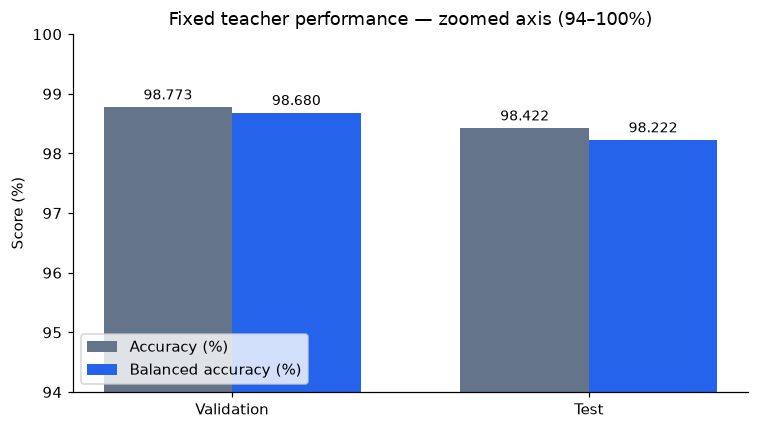

In [9]:
primary_rows = []
for split in ("val", "test"):
    metrics = bundle["metrics"][(PRIMARY_SEED, split)]
    primary_rows.append({"Split": split, "Images": metrics["n_samples"], "Accuracy (%)": 100 * metrics["accuracy"], "Balanced accuracy (%)": 100 * metrics["balanced_accuracy"]})
primary_table = pd.DataFrame(primary_rows)
display(primary_table.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2)
for offset, column, color in ((-0.18, "Accuracy (%)", "#64748b"), (0.18, "Balanced accuracy (%)", "#2563eb")):
    bars = ax.bar(x + offset, primary_table[column], width=0.36, label=column, color=color)
    ax.bar_label(bars, fmt="%.3f", fontsize=9, padding=3)
ax.set_xticks(x, ["Validation", "Test"])
ax.set(ylim=(94, 100), ylabel="Score (%)", title="Fixed teacher performance — zoomed axis (94–100%)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### 2.2 Published reference checkpoints

This table compares our recomputed results with the explicitly named `test_balanced_accuracy_per_seed` values in the checkpoint configs. The source difference is measured in **percentage points**. All three checkpoints are included because their training runs were published, not because we trained the teacher three times locally.

,Seed,Role,Validation accuracy (%),Validation balanced accuracy (%),Test accuracy (%),Test balanced accuracy (%),Source test balanced accuracy (%),Source difference (pp)
0,71397589,Fixed KD teacher,98.7734,98.6796,98.4215,98.2223,98.2223,0.0
1,133560673,Reference only,98.8902,99.0994,98.3631,98.5521,98.5521,0.0
2,265017005,Reference only,99.3575,99.4718,98.6261,98.6525,98.6525,0.0


Reference test Balanced Accuracy: 98.4756% ± 0.2251 percentage points (sample SD, n=3).
The fixed teacher remains seed 71397589 regardless of which reference checkpoint scores highest.


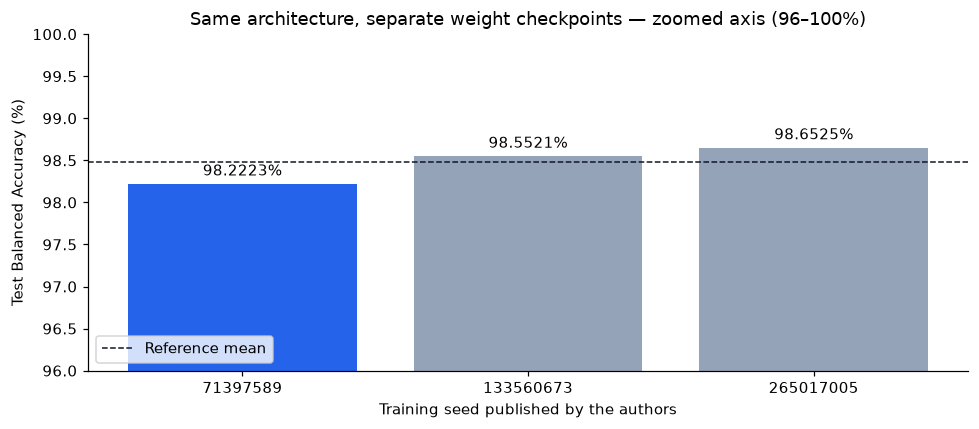

In [10]:
reference_table = teacher_table(bundle)
display(reference_table.round(4))
test_scores = reference_table["Test balanced accuracy (%)"].to_numpy()
reference_mean = test_scores.mean()
reference_sd = test_scores.std(ddof=1)
print(f"Reference test Balanced Accuracy: {reference_mean:.4f}% ± {reference_sd:.4f} percentage points (sample SD, n={len(test_scores)}).")
print("The fixed teacher remains seed", PRIMARY_SEED, "regardless of which reference checkpoint scores highest.")

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#2563eb" if int(seed) == PRIMARY_SEED else "#94a3b8" for seed in reference_table["Seed"]]
bars = ax.bar(reference_table["Seed"], test_scores, color=colors)
ax.bar_label(bars, fmt="%.4f%%", padding=3)
ax.axhline(reference_mean, color="#0f172a", linestyle="--", linewidth=1, label="Reference mean")
ax.set(ylim=(96, 100), xlabel="Training seed published by the authors", ylabel="Test Balanced Accuracy (%)", title="Same architecture, separate weight checkpoints — zoomed axis (96–100%)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### 2.3 Confusion matrices for the fixed teacher

Rows are **true classes** and columns are **predicted classes**. The left matrix shows counts; the right matrix normalizes each row to 100%. Its diagonal is the recall of each class. Row normalization makes smaller classes visible instead of letting large classes dominate the visual summary.

The matrices below use the test set and are descriptive analysis of the fixed teacher. We will not change the student design or hyperparameters based on these test errors.

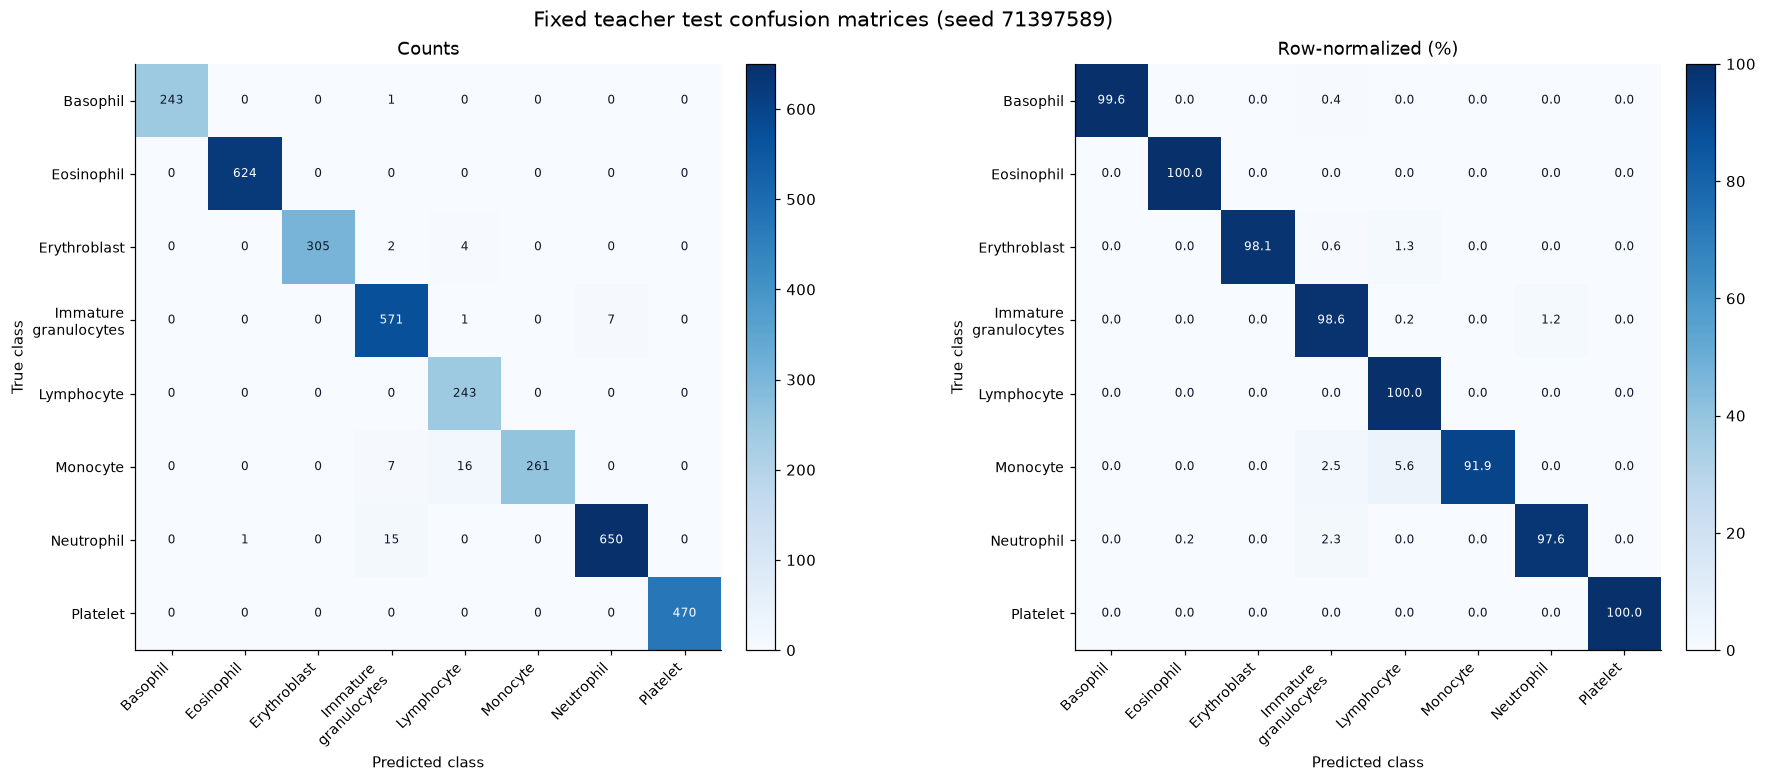

In [11]:
matrix = bundle["metrics"][(PRIMARY_SEED, "test")]["confusion_matrix"]
row_percent = 100 * matrix / matrix.sum(axis=1, keepdims=True)
plot_names = [name.replace("Immature granulocytes", "Immature\ngranulocytes") for name in short_names]
fig, axes = plt.subplots(1, 2, figsize=(17, 7), constrained_layout=True)
for ax, values, title, maximum, format_string in (
    (axes[0], matrix, "Counts", None, ".0f"),
    (axes[1], row_percent, "Row-normalized (%)", 100, ".1f"),
):
    image = ax.imshow(values, cmap="Blues", vmin=0, vmax=maximum)
    ax.set_xticks(range(8), plot_names, rotation=45, ha="right", fontsize=9)
    ax.set_yticks(range(8), plot_names, fontsize=9)
    ax.set(xlabel="Predicted class", ylabel="True class", title=title)
    threshold = (maximum if maximum is not None else values.max()) / 2
    for row in range(8):
        for column in range(8):
            ax.text(column, row, format(values[row, column], format_string), ha="center", va="center", fontsize=8, color="white" if values[row, column] > threshold else "#0f172a")
    fig.colorbar(image, ax=ax, fraction=0.04, pad=0.03)
fig.suptitle(f"Fixed teacher test confusion matrices (seed {PRIMARY_SEED})", fontsize=14)
plt.show()

### 2.4 Per-class recall and observed confusions

Support is the number of true examples of a class. Recall is the proportion of those examples classified correctly. The unweighted average of the eight recalls equals Balanced Accuracy. A high overall score does not imply equally strong performance on every class.

,Label,Class,Support,Correct,Errors,Recall (%)
0,0,basophil,244,243,1,99.590
1,1,eosinophil,624,624,0,100.000
2,2,erythroblast,311,305,6,98.071
3,3,"immature granulocytes(myelocytes, metamyelocyt...",579,571,8,98.618
4,4,lymphocyte,243,243,0,100.000
5,5,monocyte,284,261,23,91.901
6,6,neutrophil,666,650,16,97.598
7,7,platelet,470,470,0,100.000


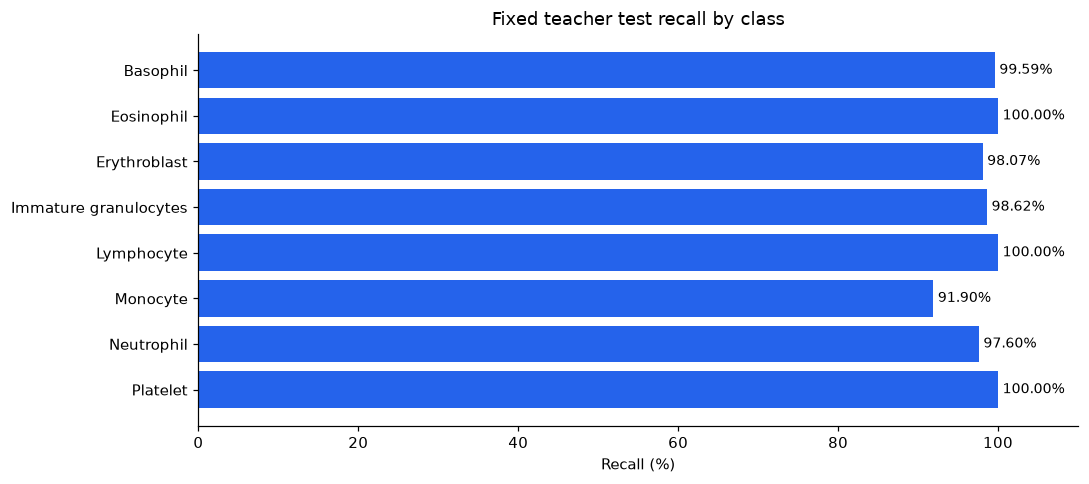

,True class,Predicted class,Images,Share of true class (%)
6,monocyte,lymphocyte,16,5.634
8,neutrophil,"immature granulocytes(myelocytes, metamyelocyt...",15,2.252
4,"immature granulocytes(myelocytes, metamyelocyt...",neutrophil,7,1.209
5,monocyte,"immature granulocytes(myelocytes, metamyelocyt...",7,2.465
2,erythroblast,lymphocyte,4,1.286
1,erythroblast,"immature granulocytes(myelocytes, metamyelocyt...",2,0.643
0,basophil,"immature granulocytes(myelocytes, metamyelocyt...",1,0.410
3,"immature granulocytes(myelocytes, metamyelocyt...",lymphocyte,1,0.173
7,neutrophil,eosinophil,1,0.150


Lowest observed test recall: monocyte (91.901%, support=284).
These are descriptive findings, not evidence for a new tuning decision.


In [12]:
class_table = per_class_table(bundle, PRIMARY_SEED, "test")
display(class_table.round(3))
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(short_names, class_table["Recall (%)"], color="#2563eb")
ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9)
ax.set(xlim=(0, 110), xlabel="Recall (%)", title="Fixed teacher test recall by class")
ax.set_xticks(np.arange(0, 101, 20))
ax.invert_yaxis()
plt.tight_layout()
plt.show()

error_rows = []
for true_class in range(8):
    for predicted_class in range(8):
        if true_class != predicted_class and matrix[true_class, predicted_class] > 0:
            error_rows.append({"True class": class_names[true_class], "Predicted class": class_names[predicted_class], "Images": int(matrix[true_class, predicted_class]), "Share of true class (%)": row_percent[true_class, predicted_class]})
error_pairs = pd.DataFrame(error_rows, columns=["True class", "Predicted class", "Images", "Share of true class (%)"]).sort_values("Images", ascending=False, kind="stable")
display(error_pairs.head(10).round(3))
weakest = class_table.loc[class_table["Recall (%)"].idxmin()]
print(f"Lowest observed test recall: {weakest['Class']} ({weakest['Recall (%)']:.3f}%, support={weakest['Support']}).")
print("These are descriptive findings, not evidence for a new tuning decision.")

### 2.5 Interpretation and limitations

- The fixed teacher reproduces its explicitly reported Balanced Accuracy. This verifies the local inference setup; it does not reproduce the original training procedure.
- Reference-checkpoint variability and later student-training variability are different quantities. The reference SD is not a confidence interval and is not an inference-time ensemble score.
- Some model-card prose contains another series of scores without a sufficiently clear metric label. We use the named metrics in `config.json` as the comparison target.
- All source revisions, weight checksums, class labels and environment versions are recorded in the saved report. The raw data file matched the official MedMNIST checksum.
- Recorded evaluation duration includes batch preparation and is **not** a latency benchmark. Model-size and latency comparisons will use a separate controlled protocol.
- Analysis mode can inspect predictions but cannot inspect arbitrary full-resolution images. The displayed training preview is a saved illustration, not a fresh dataset load.

## 3. Optional full-mode teacher reevaluation

This cell is skipped by default, even in `full` mode. Set `REEVALUATE_TEACHER=True` only to intentionally rerun the existing evaluation script with local weights, data, the full environment and CUDA. It never trains a model and does not replace the versioned result files automatically.

In [13]:
if RUN_MODE == "full" and REEVALUATE_TEACHER:
    import subprocess
    from datetime import datetime

    checkpoint_root = PROJECT_ROOT / "checkpoints" / "teachers"
    required_files = [checkpoint_root / f"seed_{seed}" / name for seed in (71397589, 133560673, 265017005) for name in ("config.json", "model.safetensors", "manifest.json")]
    if not all(path.is_file() for path in required_files):
        raise FileNotFoundError("Teacher files are missing. This notebook does not download weights automatically.")
    recheck_output = RESULTS_DIR / ("teacher_recheck_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
    subprocess.run([sys.executable, "-B", str(PROJECT_ROOT / "src" / "verify_teacher.py"), "--output", str(recheck_output)], cwd=PROJECT_ROOT, check=True)
else:
    print("Teacher reevaluation skipped. Saved results were analyzed without model inference.")

Teacher reevaluation skipped. Saved results were analyzed without model inference.


## 4. Planned student and distillation experiments — not run

The planned student is a four-block CNN (16, 32, 64, 128 channels), followed by global average pooling and an eight-class linear head. Baseline and KD runs will use the same architecture and matched initializations/data order.

The approved output-distillation search uses temperatures {1, 2, 4} and KD weights {0.5, 0.75}, selected on validation only. Final comparisons will use three paired student seeds. This notebook currently contains **no student results and no training implementation**.

Future additions will document the baseline, KD loss, validation search, paired final runs, size/latency comparisons and conclusions here, using shared implementation code in `src/`.

## 5. Reproducibility and sharing checklist

For analysis, share this notebook, `src/teacher_analysis.py`, `requirements-analysis.txt`, `results/data_summary.json`, `results/figures/data_samples.png`, `results/teacher_reference.json`, and the six prediction CSV files through Git. Also retain `configs/teachers.json`, the source-reference JSON and the verification report as provenance. Do not commit `.venv/`, `data/`, or `checkpoints/`.

On a partner machine: install `requirements-analysis.txt`, select that environment as the notebook kernel, keep `RUN_MODE='analysis'`, and run all cells. No GPU check, model import or download is part of this route.

### Sources and local records

- [Teacher verification report](../docs/teacher_verification.md)
- [Saved metrics and environment](../results/teacher_reference.json)
- [Pinned checkpoint manifests](../configs/teachers.json)
- [Model card for the fixed checkpoint](https://huggingface.co/sdoerrich97/colorist_densenet121_bloodmnist_s71397589)
- [MedMNIST data source](https://zenodo.org/records/10519652)

These links are references only executing analysis mode does not access them.